# 02a. Preprocessing Pipeline

**Owner:** Member B (Random Forest)
**Project:** Predicting district-level dengue outbreaks in Sri Lanka two weeks ahead

This notebook builds and justifies the preprocessing that **both** models use. The code lives in `src/preprocessing.py`, so Logistic Regression and Random Forest are trained on identical inputs and any difference in their results comes from the algorithms, not the data.

**Timing convention.** A prediction is made at the end of the **origin week t** about the **target week t + 2**. Every feature for week t may use data from week t and earlier, never later.

**Decisions confirmed by the group before this step**

| # | Decision | Choice |
|---|---|---|
| 1 | Outbreak label | Keep the agreed definition: cases above the district mean + 1 SD, fitted on 2007 to 2020 |
| 2 | Tuning | Expanding-window time-series cross-validation over the training years; 2021 to 2022 kept as a final check |
| 3 | Population | Replace the year-specific population columns with one constant per district: the log of its mean density over the training years |

Each preprocessing choice below cites the EDA finding that motivates it (`01a` = target notebook, `01b` = feature notebook).

In [20]:
import sys
from pathlib import Path

# Make the project root importable so the shared `src` modules work from notebooks/.
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from sklearn.feature_selection import mutual_info_classif

from src import config, viz
from src.data_loader import load_raw
from src.preprocessing import (
    CATEGORICAL_FEATURES, CV_VALIDATION_YEARS, FEATURE_DESCRIPTIONS, LOG_FEATURES,
    MODEL_FEATURES, NUMERIC_FEATURES, build_model_frame, engineer_features,
    expanding_year_folds, fit_reference_stats, get_xy, make_preprocessor,
)

viz.set_style()
pd.set_option("display.width", 140)
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

In [21]:
raw = load_raw()
reference = fit_reference_stats(raw)
frame = build_model_frame()

X_train, y_train = get_xy(frame, "train")
X_val, y_val = get_xy(frame, "val")
X_test, y_test = get_xy(frame, "test")

print(f"Raw panel:       {raw.shape[0]:,} rows x {raw.shape[1]} columns")
print(f"Modelling frame: {frame.shape[0]:,} rows")
for name, X in [("train", X_train), ("val", X_val), ("test", X_test)]:
    print(f"  {name:5s} {X.shape[0]:>6,} rows x {X.shape[1]} input columns")

Raw panel:       24,775 rows x 28 columns
Modelling frame: 24,600 rows
  train 18,200 rows x 18 input columns
  val    2,575 rows x 18 input columns
  test   3,825 rows x 18 input columns


## 1. What happens to every raw column

All 28 columns of the raw data are accounted for. The check at the end of the cell fails if any column is left without a decision.

In [22]:
column_fate = {
    "year":               ("Used for splitting only", "Encodes time; as a feature it would let the model memorise epidemic years"),
    "week":               ("Replaced by week_sin, week_cos", "Seasonality with week 52 next to week 1 (01a section 3)"),
    "start.date":         ("Key and sort order only", "Identifies the week; not a predictor"),
    "end.date":           ("Dropped: redundant", "Always start.date plus 5 to 7 days (data dictionary)"),
    "month":              ("Dropped: redundant", "Correlation 0.91 with week (01b section 7)"),
    "season":             ("Dropped: redundant", "One value per month (01b section 8)"),
    "monsoon_season":     ("Dropped: redundant", "One value per month (01b section 8)"),
    "is_epidemic_year":   ("Dropped: leaky", "Hindsight label for 2009, 2017, 2019 (01b section 8)"),
    "district":           ("Kept: one-hot encoded", "Large differences between districts (01a section 4)"),
    "province":           ("Dropped: redundant", "Fully determined by district (01b section 8)"),
    "latitude":           ("Dropped: district proxy", "One value per district; district is already encoded"),
    "longitude":          ("Dropped: district proxy", "One value per district; district is already encoded"),
    "coastal_district":   ("Dropped: district proxy", "One value per district; district is already encoded"),
    "elevation_category": ("Dropped: district proxy", "One value per district; district is already encoded"),
    "area_km2":           ("Dropped: district proxy", "One value per district; district is already encoded"),
    "population":         ("Replaced by log_density", "Acts as a district-year identifier (01b section 6.1); decision 3"),
    "population_source":  ("Dropped: metadata", "Describes data quality, not the district"),
    "population_density": ("Replaced by log_density", "Acts as a district-year identifier (01b section 6.1); decision 3"),
    "cases":              ("Target source and case features", "Builds the label and cases_now, lags, rolling means, trend, ratio"),
    "incidence_rate":     ("Dropped: leaky", "Exactly cases / population x 100,000 (01b section 8)"),
    "cases_lag1":         ("Recomputed as cases_lag1", "Rebuilt with the other lags so all share one method (values identical)"),
    "cases_zscore":       ("Dropped: leaky", "Uses the same week's cases and future statistics (01b section 8)"),
    "rainfall_mm":        ("Used in rain_recent4, rain_w5_8", "Rainfall acts about 7 to 9 weeks before cases (01b section 5)"),
    "rainfall_lag2":      ("Replaced by rain_w5_8", "Lag too short for the effect found in 01b section 5"),
    "rainfall_lag4":      ("Replaced by rain_w5_8", "Lag too short for the effect found in 01b section 5"),
    "temp_max_c":         ("Used in temp_max_anom4", "Warmer-than-usual weeks precede more cases (01b section 5)"),
    "temp_min_c":         ("Dropped: weak and collinear", "Almost no relationship with cases; r = 0.72 with temp_max (01b sections 5, 7)"),
    "humidity_pct":       ("Used in humidity_w5_8", "Humidity acts about 7 weeks before cases (01b section 5)"),
}
assert set(column_fate) == set(raw.columns), "Every raw column needs a decision"

fate = pd.DataFrame(column_fate, index=["decision", "reason"]).T
fate.index.name = "raw column"
print(fate["decision"].str.split(":").str[0].value_counts().to_string())
fate

decision
Dropped                            15
Replaced by log_density             2
Replaced by rain_w5_8               2
Used for splitting only             1
Replaced by week_sin, week_cos      1
Key and sort order only             1
Kept                                1
Target source and case features     1
Recomputed as cases_lag1            1
Used in rain_recent4, rain_w5_8     1
Used in temp_max_anom4              1
Used in humidity_w5_8               1


,decision,reason
raw column,,
year,Used for splitting only,Encodes time; as a feature it would let the model memorise epidemic years
week,"Replaced by week_sin, week_cos",Seasonality with week 52 next to week 1 (01a section 3)
start.date,Key and sort order only,Identifies the week; not a predictor
end.date,Dropped: redundant,Always start.date plus 5 to 7 days (data dictionary)
month,Dropped: redundant,Correlation 0.91 with week (01b section 7)
season,Dropped: redundant,One value per month (01b section 8)
monsoon_season,Dropped: redundant,One value per month (01b section 8)
is_epidemic_year,Dropped: leaky,"Hindsight label for 2009, 2017, 2019 (01b section 8)"
district,Kept: one-hot encoded,Large differences between districts (01a section 4)


**Note.** The plan listed latitude, longitude and area as district proxies to drop. `coastal_district` and `elevation_category` are dropped for the same reason: each takes exactly one value per district (01b section 8), so once the district itself is one-hot encoded they add no new information and only create collinearity for Logistic Regression.

## 2. Engineered features

The model receives 17 numeric features and one categorical feature (district, expanded to 25 indicator columns).

In [23]:
groups = {f: "case history" for f in LOG_FEATURES[:8] + ["cases_trend", "outbreak_now"]}
groups.update({f: "climate" for f in ["rain_recent4", "rain_w5_8", "humidity_w5_8", "temp_max_anom4"]})
groups.update({"week_sin": "calendar", "week_cos": "calendar", "log_density": "district", "district": "district"})

feature_table = pd.DataFrame({
    "group": [groups[f] for f in MODEL_FEATURES],
    "transform": ["impute, log(1 + x), scale" if f in LOG_FEATURES else
                  "impute, scale" if f in NUMERIC_FEATURES else "one-hot" for f in MODEL_FEATURES],
    "description": [FEATURE_DESCRIPTIONS[f] for f in MODEL_FEATURES],
}, index=pd.Index(MODEL_FEATURES, name="feature"))
feature_table

,group,transform,description
feature,,,
cases_now,case history,"impute, log(1 + x), scale",Cases in the origin week t
cases_lag1,case history,"impute, log(1 + x), scale",Cases in week t-1
cases_lag2,case history,"impute, log(1 + x), scale",Cases in week t-2
cases_lag3,case history,"impute, log(1 + x), scale",Cases in week t-3
cases_lag4,case history,"impute, log(1 + x), scale",Cases in week t-4
cases_roll4,case history,"impute, log(1 + x), scale",Mean weekly cases over weeks t-3 to t
cases_roll8,case history,"impute, log(1 + x), scale",Mean weekly cases over weeks t-7 to t
cases_rel_threshold,case history,"impute, log(1 + x), scale",Cases in week t divided by the district's outbreak threshold
rain_recent4,climate,"impute, log(1 + x), scale",Mean weekly rainfall over weeks t-3 to t


The example below shows Batticaloa in late 2019, the weeks before and after an outbreak begins. Reading across a row shows what the model knows at week t; the `target` column is what it must predict two weeks later.

In [24]:
example_cols = [config.DATE_COL, "cases_now", "cases_roll4", "cases_trend", "cases_rel_threshold",
                "outbreak_now", "rain_w5_8", "temp_max_anom4", "target"]
example = frame[(frame[config.DISTRICT_COL] == "Batticaloa")
                & frame[config.DATE_COL].between("2019-09-14", "2019-11-16")]
example[example_cols].set_index(config.DATE_COL)

,cases_now,cases_roll4,cases_trend,cases_rel_threshold,outbreak_now,rain_w5_8,temp_max_anom4,target
start.date,,,,,,,,
2019-09-14,12,16.250,-0.571,0.144,0,7.300,-0.090,0
2019-09-21,17,16.000,-0.054,0.204,0,20.100,-1.084,0
2019-09-28,24,16.750,0.128,0.289,0,22.275,-2.217,0
2019-10-05,39,23.000,0.981,0.469,0,23.175,-3.145,0
2019-10-12,39,29.750,1.124,0.469,0,31.575,-2.957,0
2019-10-19,52,38.500,1.080,0.625,0,30.050,-2.532,1
2019-10-26,67,49.250,1.001,0.805,0,34.775,-2.146,1
2019-11-02,92,62.500,0.844,1.106,1,38.875,-1.240,1
2019-11-09,97,77.000,0.896,1.166,1,39.025,-0.540,1


In these rows, `target` switches to 1 two weeks before `outbreak_now` does, because it looks two weeks ahead. In the weeks just before that switch, `cases_now` and `cases_rel_threshold` are already climbing and `cases_trend` is positive, while `outbreak_now` is still 0. Recognising that build-up before the threshold is crossed is exactly what the models must learn, and it is where the persistence baseline (predict "outbreak in two weeks" only if there is one now) always fails.

## 3. Leakage tests

These tests check the guarantees in code rather than asserting them in prose.

### 3.1 No feature looks into the future

If a feature at week t used any later week, deleting the later weeks would change it. The test cuts the raw data off at several origin weeks, including points next to the split boundaries, rebuilds the features from the truncated data, and checks that the features at the cut-off week are unchanged.

In [25]:
numeric_features = LOG_FEATURES + NUMERIC_FEATURES
full = engineer_features(raw, reference).set_index([config.DISTRICT_COL, config.DATE_COL])

cut_offs = ["2010-06-05", "2017-03-04", "2020-12-19", "2021-06-05", "2022-12-24", "2024-01-06"]
results = []
for cut in pd.to_datetime(cut_offs):
    truncated = engineer_features(raw[raw[config.DATE_COL] <= cut], reference)
    last_week = truncated[config.DATE_COL].max()
    rebuilt = truncated[truncated[config.DATE_COL] == last_week].set_index([config.DISTRICT_COL, config.DATE_COL])
    original = full.loc[rebuilt.index]
    identical = np.allclose(rebuilt[numeric_features].to_numpy(dtype=float),
                            original[numeric_features].to_numpy(dtype=float), equal_nan=True)
    results.append({"cut-off week": last_week.date(), "districts checked": len(rebuilt), "features unchanged": identical})

lookahead = pd.DataFrame(results)
assert lookahead["features unchanged"].all(), "A feature uses data from after week t"
lookahead

,cut-off week,districts checked,features unchanged
0,2010-06-05,25,True
1,2017-03-04,25,True
2,2020-12-19,25,True
3,2021-06-05,25,True
4,2022-12-24,25,True
5,2024-01-06,25,True


### 3.2 Learned statistics come from training years only

Three quantities are learned from data: the outbreak thresholds, the temperature baseline used for the anomaly, and the district density constant. The test scrambles every value outside 2007 to 2020 and refits them. If they change, something is reading validation or test data.

In [26]:
scrambled = raw.copy()
outside_training = ~scrambled["year"].between(*config.TRAIN_YEARS)
rng = np.random.default_rng(config.RANDOM_SEED)
for col in [config.CASES_COL, "temp_max_c", "population_density"]:
    scrambled[col] = scrambled[col].astype(float)
    scrambled.loc[outside_training, col] *= rng.uniform(0.2, 5.0, outside_training.sum())

refit = fit_reference_stats(scrambled)
unchanged = {name: bool(np.allclose(reference[name], refit[name])) for name in reference}
assert all(unchanged.values())
pd.Series(unchanged, name="unchanged after scrambling non-training years").to_frame()

,unchanged after scrambling non-training years
thresholds,True
temp_baseline,True
log_density,True


### 3.3 Excluded columns cannot reach the model

In [27]:
forbidden = set(config.LEAKY_COLUMNS) | {"year", "target", "target_year", config.CASES_COL, "population", "population_density"}
assert not forbidden & set(MODEL_FEATURES), forbidden & set(MODEL_FEATURES)

recomputed_matches = np.allclose(full["cases_lag1"].to_numpy(dtype=float),
                                 raw.set_index([config.DISTRICT_COL, config.DATE_COL])["cases_lag1"]
                                    .reindex(full.index).to_numpy(dtype=float), equal_nan=True)
print("No leaky or excluded column is among the model features.")
print(f"Recomputed cases_lag1 equals the dataset's own column: {recomputed_matches}")

No leaky or excluded column is among the model features.
Recomputed cases_lag1 equals the dataset's own column: True


**Result.** All three tests pass. Features look backwards only, every learned statistic comes from the training years, and the leaky columns are excluded by construction. Imputation and scaling are inside the scikit-learn pipeline (section 6), so they are refitted on the training part of every cross-validation fold automatically.

## 4. Transformations

Case counts and rainfall are heavily right-skewed (01a section 1, 01b section 2). A log(1 + x) transform is applied to them before scaling.

In [28]:
skew = pd.DataFrame({
    "skewness before": X_train[LOG_FEATURES].skew(),
    "skewness after log(1 + x)": np.log1p(X_train[LOG_FEATURES]).skew(),
})
skew

,skewness before,skewness after log(1 + x)
cases_now,10.498,0.303
cases_lag1,10.500,0.303
cases_lag2,10.495,0.302
cases_lag3,10.489,0.302
cases_lag4,10.483,0.301
cases_roll4,9.908,0.352
cases_roll8,8.787,0.348
cases_rel_threshold,5.052,2.413
rain_recent4,1.651,-0.488
rain_w5_8,1.669,-0.481


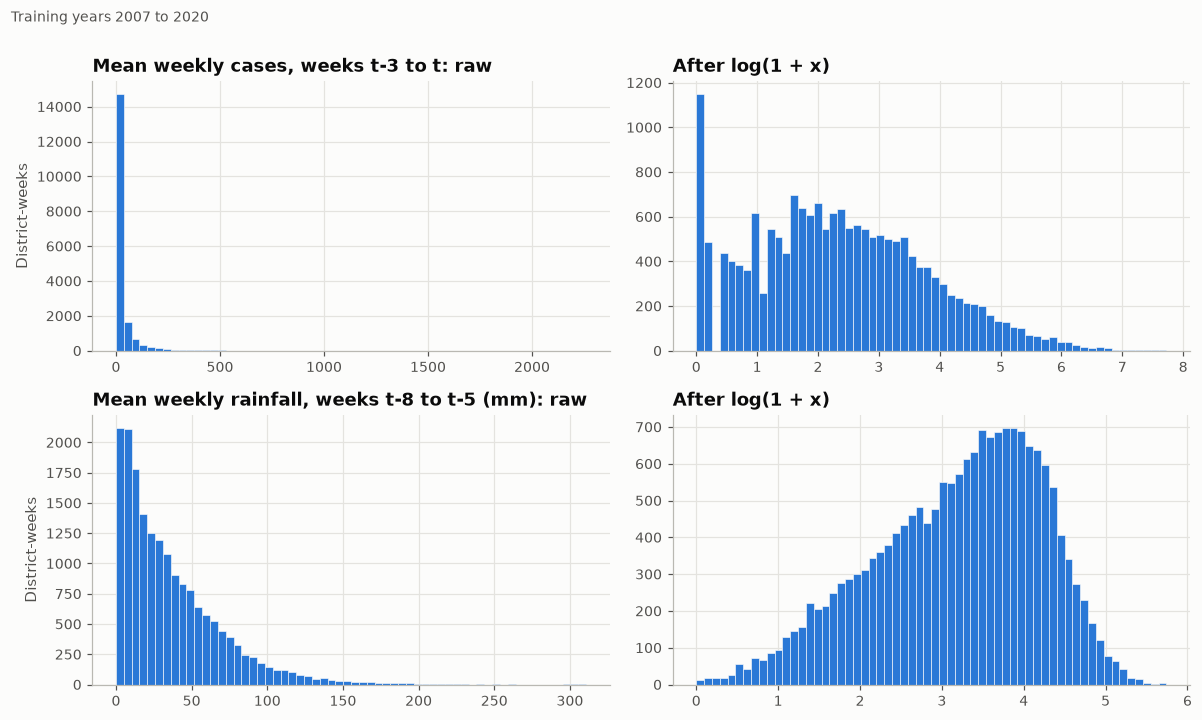

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(11, 6.5))
for row, (col, label) in enumerate([("cases_roll4", "Mean weekly cases, weeks t-3 to t"),
                                    ("rain_w5_8", "Mean weekly rainfall, weeks t-8 to t-5 (mm)")]):
    values = X_train[col].dropna()
    axes[row, 0].hist(values, bins=60, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=0.4)
    axes[row, 0].set_title(f"{label}: raw")
    axes[row, 1].hist(np.log1p(values), bins=60, color=viz.BLUE, edgecolor=viz.SURFACE, linewidth=0.4)
    axes[row, 1].set_title("After log(1 + x)")
    axes[row, 0].set_ylabel("District-weeks")
fig.suptitle("Training years 2007 to 2020", x=0.01, ha="left", fontsize=9, color=viz.TEXT_MUTED, y=1.0)
fig.tight_layout()
viz.save(fig, "prep_01_log_transform")
plt.show()

In [30]:
ratio = X_train["cases_rel_threshold"]
threshold = X_train[config.DISTRICT_COL].map(reference["thresholds"])
log_ratio = np.log1p(X_train["cases_now"]) - np.log1p(threshold)

ratio_options = pd.DataFrame({
    "skewness": [np.log1p(ratio).skew(), log_ratio.skew()],
    "correlation with target": [np.corrcoef(np.log1p(ratio), y_train)[0, 1], np.corrcoef(log_ratio, y_train)[0, 1]],
}, index=["log(1 + cases / threshold)  (used)", "log((1 + cases) / (1 + threshold))  (rejected)"])
ratio_options

,skewness,correlation with target
log(1 + cases / threshold) (used),2.413,0.680
log((1 + cases) / (1 + threshold)) (rejected),-0.029,0.495


**Finding.** The transform removes almost all skew from the case and rainfall features (case features fall from about 10 to about 0.3). One feature keeps some skew on purpose: `cases_rel_threshold`. Its symmetric alternative (a log ratio) removes the skew but is noticeably less related to the target, because the useful information sits in the upper tail, where a district's cases approach or exceed its threshold. The more informative version is kept.

The log transform matters for Logistic Regression, whose linear boundary would otherwise be dominated by a few extreme weeks. It has no effect on Random Forest, whose splits depend only on the order of values, which a log transform preserves.

## 5. Missing values

Lags and rolling windows need earlier weeks, which do not exist at the very start of each district's series.

In [31]:
missing = frame.groupby("split")[numeric_features].apply(lambda d: d.isna().sum()).T
missing = missing.loc[missing.sum(axis=1) > 0, ["train", "val", "test"]]
missing["share of training rows (%)"] = 100 * missing["train"] / len(X_train)
missing

split,train,val,test,share of training rows (%)
cases_lag2,25,0,0,0.137
cases_lag3,50,0,0,0.275
cases_lag4,75,0,0,0.412
cases_roll4,50,0,0,0.275
cases_roll8,150,0,0,0.824
rain_recent4,50,0,0,0.275
rain_w5_8,175,0,0,0.962
cases_trend,75,0,0,0.412
humidity_w5_8,175,0,0,0.962
temp_max_anom4,50,0,0,0.275


In [32]:
first_missing_week = frame.loc[frame[numeric_features].isna().any(axis=1), config.DATE_COL]
print(f"Rows with any missing feature: {frame[numeric_features].isna().any(axis=1).sum()} "
      f"({100 * frame[numeric_features].isna().any(axis=1).mean():.2f}% of all rows)")
print(f"All of them fall between {first_missing_week.min().date()} and {first_missing_week.max().date()}")

Rows with any missing feature: 175 (0.71% of all rows)
All of them fall between 2006-12-30 and 2007-02-10


**Finding.** Missing values are rare (under 1% of training rows), confined to the first seven weeks of the training period (175 rows: 7 weeks x 25 districts), and absent from validation and test.

**Decision.** Impute with the training median inside the pipeline instead of dropping the rows. Imputing keeps the full early-2007 history, and because the imputer is part of the pipeline it learns its medians from the training portion only, including inside every cross-validation fold.

## 6. The fitted preprocessing pipeline

`make_preprocessor()` returns an unfitted scikit-learn `ColumnTransformer`:

| Branch | Features | Steps |
|---|---|---|
| `log` | 10 skewed count and rainfall features | median imputation, log(1 + x), standardisation |
| `num` | 7 other numeric features | median imputation, standardisation |
| `district` | district | one-hot encoding (unknown districts ignored) |

Here it is fitted on the training split only and then applied to all three splits.

In [33]:
preprocessor = make_preprocessor().fit(X_train)
feature_names = preprocessor.get_feature_names_out()

transformed = {name: preprocessor.transform(X) for name, X in [("train", X_train), ("val", X_val), ("test", X_test)]}
pd.DataFrame({
    "rows": {k: v.shape[0] for k, v in transformed.items()},
    "model inputs": {k: v.shape[1] for k, v in transformed.items()},
    "missing values": {k: int(np.isnan(v).sum()) for k, v in transformed.items()},
}).T

,train,val,test
rows,18200,2575,3825
model inputs,42,42,42
missing values,0,0,0


In [34]:
n_numeric = len(numeric_features)
train_numeric = transformed["train"][:, :n_numeric]
print(f"Model inputs: {len(feature_names)} = {n_numeric} numeric + {len(feature_names) - n_numeric} district indicators")
print(f"Numeric inputs on training data: mean within {np.abs(train_numeric.mean(axis=0)).max():.1e} of 0, "
      f"standard deviation between {train_numeric.std(axis=0).min():.3f} and {train_numeric.std(axis=0).max():.3f}")

imputer_medians = pd.Series(
    preprocessor.named_transformers_["log"].named_steps["impute"].statistics_, index=LOG_FEATURES
)
print("\nMedians learned by the imputer (training data, before the log transform):")
print(imputer_medians.round(2).to_string())

Model inputs: 42 = 17 numeric + 25 district indicators
Numeric inputs on training data: mean within 1.6e-14 of 0, standard deviation between 1.000 and 1.000

Medians learned by the imputer (training data, before the log transform):
cases_now              8.000
cases_lag1             8.000
cases_lag2             8.000
cases_lag3             8.000
cases_lag4             8.000
cases_roll4            8.500
cases_roll8            9.000
cases_rel_threshold    0.150
rain_recent4          27.480
rain_w5_8             27.220


**Result.** All three splits produce 42 model inputs with no missing values, and the numeric inputs are centred with unit variance on the training data. Validation and test are transformed with the training statistics, never their own.

Standardisation is required for Logistic Regression, because regularisation penalises coefficients by size and needs features on a common scale. Random Forest ignores it. Using one pipeline for both keeps the comparison clean: the inputs are identical, and only the algorithm differs.

## 7. Did the engineering add information?

The engineered features were designed from the EDA. This section checks, on training years only, whether they carry more information about the target than the raw columns they replace. Mutual information is used because it captures non-linear relationships (lecture 2, filter methods). This is a check of the preprocessing, not feature selection, which is step 8.

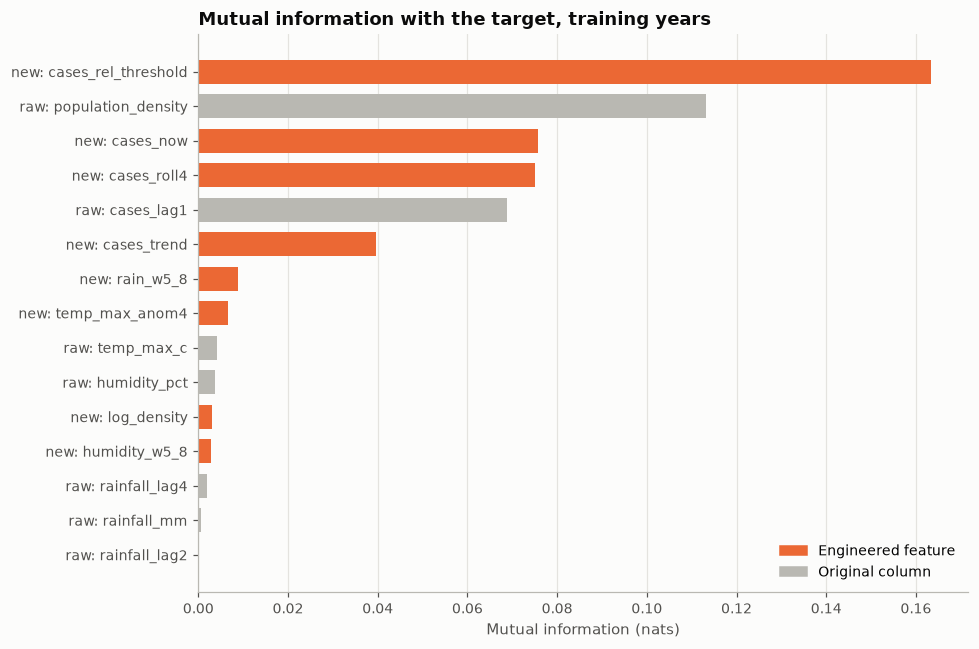

,mutual information
new: cases_rel_threshold,0.163
raw: population_density,0.113
new: cases_now,0.076
new: cases_roll4,0.075
raw: cases_lag1,0.069
new: cases_trend,0.040
new: rain_w5_8,0.009
new: temp_max_anom4,0.006
raw: temp_max_c,0.004
raw: humidity_pct,0.004


In [35]:
originals = ["cases_lag1", "rainfall_mm", "rainfall_lag2", "rainfall_lag4", "humidity_pct", "temp_max_c", "population_density"]
engineered = ["cases_now", "cases_roll4", "cases_rel_threshold", "cases_trend", "rain_w5_8",
              "humidity_w5_8", "temp_max_anom4", "log_density"]

train_raw_cols = frame[frame["split"] == "train"][[config.DISTRICT_COL, config.DATE_COL]].merge(
    raw[[config.DISTRICT_COL, config.DATE_COL] + originals], on=[config.DISTRICT_COL, config.DATE_COL], how="left")
candidates = pd.concat([train_raw_cols[originals].add_prefix("raw: "),
                        X_train[engineered].add_prefix("new: ")], axis=1)
candidates = candidates.fillna(candidates.median())

information = pd.Series(
    mutual_info_classif(candidates, y_train, random_state=config.RANDOM_SEED), index=candidates.columns
).sort_values()

fig, ax = plt.subplots(figsize=(9, 6))
colours = [viz.ORANGE if name.startswith("new") else viz.NEUTRAL for name in information.index]
ax.barh(information.index, information.values, color=colours, height=0.7)
ax.legend(handles=[Patch(color=viz.ORANGE, label="Engineered feature"),
                   Patch(color=viz.NEUTRAL, label="Original column")], loc="lower right")
ax.set_title("Mutual information with the target, training years")
ax.set_xlabel("Mutual information (nats)")
ax.grid(axis="y", visible=False)
fig.tight_layout()
viz.save(fig, "prep_02_feature_information")
plt.show()

information.sort_values(ascending=False).round(4).to_frame("mutual information")

**Reading the result.**

* `cases_rel_threshold` (cases relative to the district's threshold) carries the most information of any feature, more than twice the original `cases_lag1`. Scaling each district by its own threshold puts large and small districts on one scale. `cases_now` and `cases_roll4` also edge past the original lag.
* The rainfall window `rain_w5_8` carries several times more information than the original rainfall columns, and the temperature anomaly more than raw maximum temperature, as the lag analysis in 01b predicted. The humidity window is no better than the original humidity column; it is kept for now and step 8 will test whether it earns its place. All climate signals remain small in absolute terms, and differences this small are within the noise of the estimator.
* `log_density` carries far less information than `population_density`. That is the intended effect of decision 3: the old column's apparent information came from identifying the year, which the district constant removes.

## 8. Time-series cross-validation folds

Decision 2 replaces tuning on the small validation block with expanding-window cross-validation inside the training years. For each validation year the model trains on all earlier years. Training rows whose target week falls in the validation year are left out, the same two-week embargo used between the main splits. Both members must use these exact folds.

In [36]:
train_frame = frame[frame["split"] == "train"].reset_index(drop=True)
folds = expanding_year_folds(train_frame)

fold_table = pd.DataFrame([{
    "validation year": year,
    "training years": f"{train_frame['year'].iloc[tr].min()} to {train_frame['year'].iloc[tr].max()}",
    "training rows": len(tr),
    "training outbreaks": int(train_frame["target"].iloc[tr].sum()),
    "validation rows": len(va),
    "validation outbreaks": int(train_frame["target"].iloc[va].sum()),
    "validation outbreak rate (%)": 100 * train_frame["target"].iloc[va].mean(),
    "latest training target year": int(train_frame["target_year"].iloc[tr].max()),
} for year, (tr, va) in zip(CV_VALIDATION_YEARS, folds)]).set_index("validation year")

assert (fold_table["latest training target year"] < fold_table.index).all()
fold_table

,training years,training rows,training outbreaks,validation rows,validation outbreaks,validation outbreak rate (%),latest training target year
validation year,,,,,,,
2016,2007 to 2015,11675,195,1325,59,4.453,2015
2017,2007 to 2016,13000,244,1300,666,51.231,2016
2018,2007 to 2017,14300,902,1300,103,7.923,2017
2019,2007 to 2018,15600,1021,1300,357,27.462,2018
2020,2007 to 2019,16900,1349,1250,74,5.920,2019


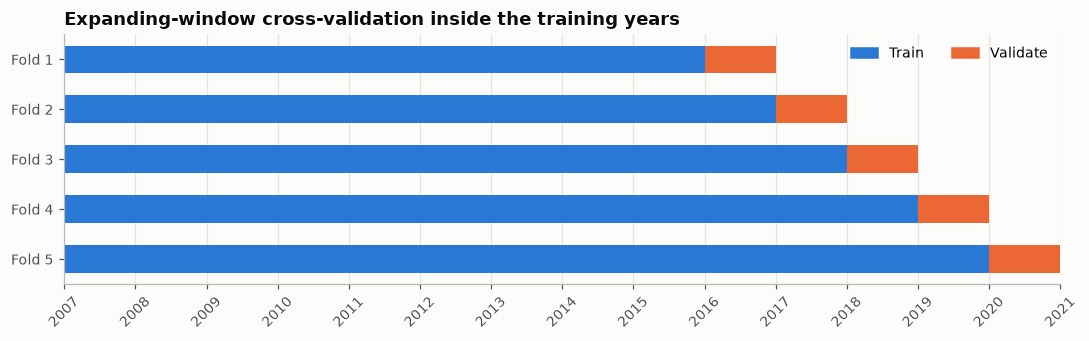

In [37]:
fig, ax = plt.subplots(figsize=(10, 3.2))
for i, year in enumerate(CV_VALIDATION_YEARS):
    ax.barh(i, year - config.TRAIN_YEARS[0], left=config.TRAIN_YEARS[0], height=0.55, color=viz.BLUE)
    ax.barh(i, 1, left=year, height=0.55, color=viz.ORANGE)
ax.set_yticks(range(len(CV_VALIDATION_YEARS)))
ax.set_yticklabels([f"Fold {i + 1}" for i in range(len(CV_VALIDATION_YEARS))])
ax.invert_yaxis()
ax.set_xticks(range(config.TRAIN_YEARS[0], config.TRAIN_YEARS[1] + 2))
ax.tick_params(axis="x", rotation=45)
ax.set_xlim(config.TRAIN_YEARS[0], config.TRAIN_YEARS[1] + 1)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=viz.BLUE, label="Train"), Patch(color=viz.ORANGE, label="Validate")],
          loc="upper right", ncol=2)
ax.set_title("Expanding-window cross-validation inside the training years")
fig.tight_layout()
viz.save(fig, "prep_03_cv_folds")
plt.show()

**Finding.** The five folds cover very different conditions: quiet years (2016, 2018, 2020), the 2017 epidemic and the 2019 surge. A model chosen by its average score across these folds has to work in both regimes, which is a more demanding test than the 77 outbreak rows of 2021 to 2022.

**Known limitation.** The outbreak threshold is part of the label definition and is fixed once from 2007 to 2020. Inside cross-validation it therefore carries a little information from later training years into the earlier folds (for example, 2017's size influences the threshold used when validating on 2016). This can make cross-validation scores slightly optimistic. It does not affect the validation and test results, whose labels never use data from 2021 onwards. This should be stated in the report's limitations.

In [38]:
config.METRICS_DIR.mkdir(parents=True, exist_ok=True)
fate.to_csv(config.METRICS_DIR / "preprocessing_column_decisions.csv")
feature_table.to_csv(config.METRICS_DIR / "preprocessing_features.csv")
fold_table.to_csv(config.METRICS_DIR / "cv_folds.csv")
print("Saved column decisions, feature list and CV folds to results/metrics/")

Saved column decisions, feature list and CV folds to results/metrics/


## 9. Summary and hand-off

**How the model notebooks use this step**

```python
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from src.preprocessing import build_model_frame, expanding_year_folds, get_xy, make_preprocessor

frame = build_model_frame()
X_train, y_train = get_xy(frame, "train")
folds = expanding_year_folds(frame[frame["split"] == "train"].reset_index(drop=True))

model = Pipeline([("prep", make_preprocessor()), ("clf", SomeClassifier())])
search = GridSearchCV(model, param_grid, cv=folds, scoring="average_precision")
```

Because preprocessing sits inside the pipeline, every fold refits the imputer and scaler on its own training rows.

**What this step delivered**

| Rubric need (criterion 3) | Where it is addressed |
|---|---|
| Cleansing | Leaky, redundant and proxy columns removed with a reason for each (section 1) |
| Leakage control | Three automated tests (section 3) and fold-aware pipeline (sections 6, 8) |
| Transformation | log(1 + x) for skewed features, cyclical week, standardisation (sections 2, 4, 6) |
| Missing values | Median imputation fitted on training data only (section 5) |
| Feature engineering | Case history, threshold ratio, climate at the lag found in EDA, temperature anomaly (sections 2, 7) |

**Next: step 8 (`02b_feature_selection.ipynb`).** Compare the full feature set with a reduced one, using a filter method and PCA, and report what each costs or gains in cross-validated PR-AUC.